# Example 6: Solving Partial Differential Equation (PDE)

We aim to solve a 2D poisson equation $\nabla^2 f(x,y) = -2\pi^2{\rm sin}(\pi x){\rm sin}(\pi y)$, with boundary condition $f(-1,y)=f(1,y)=f(x,-1)=f(x,1)=0$. The ground truth solution is $f(x,y)={\rm sin}(\pi x){\rm sin}(\pi y)$.

In [1]:
import torch
from xkan import KANNetwork
from xkan.nn import update_grids
from xkan.train import LBFGS
import matplotlib.pyplot as plt
from torch import autograd
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

dim = 2
np_i = 21 # number of interior points (along each dimension)
np_b = 21 # number of boundary points (along each dimension)
ranges = [-1, 1]

model = KANNetwork([2, 2, 1], grid=5, k=3, seed=1, device=device)
# in pykan 0.2 the network's seed also seeded torch's global generator, from which x_i is drawn below;
# KANNetwork's seed seeds only the network's parameters
torch.manual_seed(1)

def batch_jacobian(func, x, create_graph=False):
    # x in shape (Batch, Length)
    def _func_sum(x):
        return func(x).sum(dim=0)
    return autograd.functional.jacobian(_func_sum, x, create_graph=create_graph).permute(1,0,2)

# define solution
sol_fun = lambda x: torch.sin(torch.pi*x[:,[0]])*torch.sin(torch.pi*x[:,[1]])
source_fun = lambda x: -2*torch.pi**2 * torch.sin(torch.pi*x[:,[0]])*torch.sin(torch.pi*x[:,[1]])

# interior
sampling_mode = 'random' # 'radnom' or 'mesh'

x_mesh = torch.linspace(ranges[0],ranges[1],steps=np_i)
y_mesh = torch.linspace(ranges[0],ranges[1],steps=np_i)
X, Y = torch.meshgrid(x_mesh, y_mesh, indexing="ij")
if sampling_mode == 'mesh':
    #mesh
    x_i = torch.stack([X.reshape(-1,), Y.reshape(-1,)]).permute(1,0)
else:
    #random
    x_i = torch.rand((np_i**2,2))*2-1
    
x_i = x_i.to(device)

# boundary, 4 sides
helper = lambda X, Y: torch.stack([X.reshape(-1,), Y.reshape(-1,)]).permute(1,0)
xb1 = helper(X[0], Y[0])
xb2 = helper(X[-1], Y[0])
xb3 = helper(X[:,0], Y[:,0])
xb4 = helper(X[:,0], Y[:,-1])
x_b = torch.cat([xb1, xb2, xb3, xb4], dim=0)

x_b = x_b.to(device)

steps = 20
alpha = 0.01
log = 1

def train():
    optimizer = LBFGS(model.parameters(), lr=1, history_size=10, line_search_fn="strong_wolfe", tolerance_grad=1e-32, tolerance_change=1e-32, tolerance_ys=1e-32)

    pbar = tqdm(range(steps), desc='description', ncols=100)

    for _ in pbar:
        def closure():
            global pde_loss, bc_loss
            optimizer.zero_grad()
            # interior loss
            sol = sol_fun(x_i)
            sol_D1_fun = lambda x: batch_jacobian(model, x, create_graph=True)[:,0,:]
            sol_D1 = sol_D1_fun(x_i)
            sol_D2 = batch_jacobian(sol_D1_fun, x_i, create_graph=True)[:,:,:]
            lap = torch.sum(torch.diagonal(sol_D2, dim1=1, dim2=2), dim=1, keepdim=True)
            source = source_fun(x_i)
            pde_loss = torch.mean((lap - source)**2)

            # boundary loss
            bc_true = sol_fun(x_b)
            bc_pred = model(x_b)
            bc_loss = torch.mean((bc_pred-bc_true)**2)

            loss = alpha * pde_loss + bc_loss
            loss.backward()
            return loss

        if _ % 5 == 0 and _ < 50:
            update_grids(model, x_i)

        optimizer.step(closure)
        sol = sol_fun(x_i)
        loss = alpha * pde_loss + bc_loss
        l2 = torch.mean((model(x_i) - sol)**2)

        if _ % log == 0:
            pbar.set_description("pde loss: %.2e | bc loss: %.2e | l2: %.2e " % (pde_loss.cpu().detach().numpy(), bc_loss.cpu().detach().numpy(), l2.cpu().detach().numpy()))

    print("pde loss: %.2e | bc loss: %.2e | l2: %.2e " % (pde_loss.cpu().detach().numpy(), bc_loss.cpu().detach().numpy(), l2.cpu().detach().numpy()))

train()

cuda


pde loss: 2.04e+00 | bc loss: 8.63e-03 | l2: 5.24e-03 


Plot the trained KAN

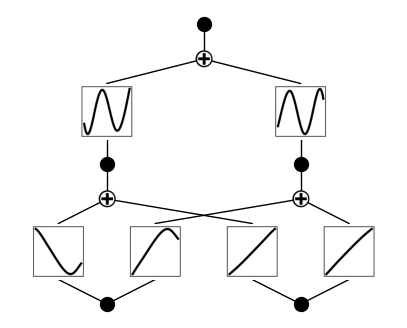

In [2]:
from xkan.viz import plot

plot(model, x_i, beta=10);

Fix the first layer activation to be linear function, and the second layer to be sine functions (caveat: this is quite sensitive to hypreparams)

In [3]:
from xkan.symbolic import fix_symbolic

# each edge fitted to its activations on the interior points (verbose: print the fit's r2)
fix_symbolic(model, 0, 0, 0, 'x', x_i, verbose=True)
fix_symbolic(model, 0, 0, 1, 'x', x_i, verbose=True)
fix_symbolic(model, 0, 1, 0, 'x', x_i, verbose=True)
fix_symbolic(model, 0, 1, 1, 'x', x_i, verbose=True)
fix_symbolic(model, 1, 0, 0, 'sin', x_i, verbose=True)
fix_symbolic(model, 1, 1, 0, 'sin', x_i, verbose=True)

r2 is 0.860519289970398
r2 is not very high, please double check if you are choosing the correct symbolic function.
Best value at boundary.
r2 is 0.8574259877204895
r2 is not very high, please double check if you are choosing the correct symbolic function.
r2 is 0.9994445443153381
r2 is 0.9986701011657715
r2 is 0.9952051043510437
r2 is 0.9862083196640015


tensor(0.9862, device='cuda:0')

After setting all to be symbolic, we further train the model (affine parameters are still trainable). The model can now reach machine precision!

In [4]:
train()

pde loss: 8.67e-12 | bc loss: 1.90e-14 | l2: 2.42e-14 


Print out the symbolic formula

In [5]:
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round

formula = symbolic_formula(model)[0][0]
ex_round(formula,6)

0.5*sin(3.141593*x_1 - 3.141593*x_2 + 1.570796) + 0.5*sin(3.141593*x_1 + 3.141593*x_2 + 4.712389)